# Linear regression to mixed models

When people reproduce a duration they have just experienced, short durations come out too long
and long durations too short. Their reproductions are pulled towards the mean of the durations
in the session. This **central-tendency effect** is one of the most robust findings in timing,
and a straight line is enough to measure it: the slope of reproduced on presented duration is
below 1, and $1 - \text{slope}$ indexes how strongly the prior pulls.

This notebook builds linear regression from its matrix form, then extends it to several
predictors and finally to a linear mixed model.

**The experiment.** Participants held 1, 3, or 5 items in visual working memory while they
encoded and reproduced a duration between 0.5 and 1.7 s. Does a heavier memory load change the
central tendency? The data are from
[msenselab/working_memory_reproduction](https://github.com/msenselab/working_memory_reproduction);
we use Experiment 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})

URL = ("https://raw.githubusercontent.com/msenselab/working_memory_reproduction/"
       "HEAD/data/AllValidData.csv")
df = (pd.read_csv(URL).query("Exp == 'Exp1'")
        .rename(columns={"NSub": "subject", "curDur": "duration", "repDur": "reproduction",
                         "WMSize": "load"})
        [["subject", "load", "duration", "reproduction"]])
print(df.describe().round(3))

        subject      load  duration  reproduction
count  5744.000  5744.000  5744.000      5744.000
mean      8.503     3.000     1.099         1.032
std       4.613     1.633     0.424         0.345
min       1.000     1.000     0.500         0.102
25%       4.000     1.000     0.800         0.774
50%       9.000     3.000     1.100         1.014
75%      13.000     5.000     1.400         1.259
max      16.000     5.000     1.700         2.486


## The model in matrix form

For $n$ trials, a straight line $y_i = \beta_0 + \beta_1 x_i + \varepsilon_i$ stacks into

$$\mathbf y = X\boldsymbol\beta + \boldsymbol\varepsilon, \qquad
X = \begin{bmatrix} 1 & x_1 \\ \vdots & \vdots \\ 1 & x_n \end{bmatrix}.$$

The least-squares estimate minimises $\lVert \mathbf y - X\boldsymbol\beta \rVert^2$. Setting the
gradient to zero gives the *normal equations*, $X^\top X \boldsymbol\beta = X^\top \mathbf y$, so

$$\hat{\boldsymbol\beta} = (X^\top X)^{-1} X^\top \mathbf y .$$

The column of ones is what gives the line an intercept. Every predictor added later is just
another column of $X$.

We fit one participant first.

In [2]:
one = df.query("subject == 1")
X = np.column_stack([np.ones(len(one)), one["duration"]])
y = one["reproduction"].to_numpy()

beta_normal = np.linalg.solve(X.T @ X, X.T @ y)
beta_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None)
print("normal equations:", beta_normal.round(4))
print("np.linalg.lstsq: ", beta_lstsq.round(4))

normal equations: [0.678  0.2425]
np.linalg.lstsq:  [0.678  0.2425]


`np.linalg.lstsq` solves the same problem with a numerically safer decomposition; in practice,
use it, or a library, rather than inverting $X^\top X$.

## Standard errors

The residual variance $\hat\sigma^2 = \lVert \mathbf y - X\hat{\boldsymbol\beta}\rVert^2/(n-p)$
gives the covariance of the estimates, $\hat\sigma^2 (X^\top X)^{-1}$. The square roots of its
diagonal are the standard errors that every regression table prints.

In [3]:
resid = y - X @ beta_lstsq
n_obs, p = X.shape
sigma2 = resid @ resid / (n_obs - p)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ X)))
print("by hand:     beta =", beta_lstsq.round(4), " SE =", se.round(4))

fit = smf.ols("reproduction ~ duration", data=one).fit()
print("statsmodels: beta =", fit.params.values.round(4), " SE =", fit.bse.values.round(4))

by hand:     beta = [0.678  0.2425]  SE = [0.0284 0.0241]
statsmodels: beta = [0.678  0.2425]  SE = [0.0284 0.0241]


`statsmodels` formulas (`y ~ x`) build the design matrix for us, including the intercept.

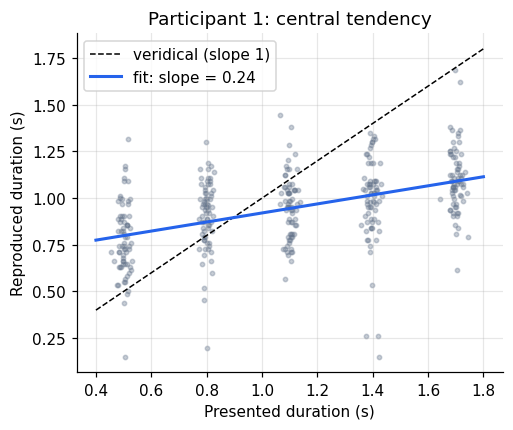

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
jitter = np.random.default_rng(0).normal(0, 0.015, len(one))
ax.scatter(one["duration"] + jitter, one["reproduction"], s=8, alpha=0.35, color="#64748b")
xs = np.linspace(0.4, 1.8, 2)
ax.plot(xs, xs, "k--", lw=1, label="veridical (slope 1)")
ax.plot(xs, beta_lstsq[0] + beta_lstsq[1] * xs, color="#2563eb", lw=2,
        label=f"fit: slope = {beta_lstsq[1]:.2f}")
ax.set(xlabel="Presented duration (s)", ylabel="Reproduced duration (s)",
       title="Participant 1: central tendency")
ax.legend()
plt.show()

The fitted line crosses the identity line inside the stimulus range. Below that point
reproductions overshoot, above it they undershoot. With a slope of about 0.24, this participant's
reproductions are dominated by the prior.

## Several predictors

Memory load enters as a second predictor. Treating it as categorical, `C(load)`, adds a dummy
column per level beyond the first; the interaction `duration:C(load)` lets the slope differ
between loads. Centering duration at its mean (1.1 s) makes the intercept the reproduction at
the mean duration rather than at the meaningless value 0 s.

In [5]:
df["dur_c"] = df["duration"] - df["duration"].mean()
ols_all = smf.ols("reproduction ~ dur_c * C(load)", data=df).fit()
print(ols_all.summary().tables[1])

                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.0338      0.005    187.996      0.000       1.023       1.045
C(load)[T.3]           0.0004      0.008      0.047      0.962      -0.015       0.016
C(load)[T.5]          -0.0046      0.008     -0.593      0.553      -0.020       0.011
dur_c                  0.5926      0.013     45.699      0.000       0.567       0.618
dur_c:C(load)[T.3]    -0.0045      0.018     -0.245      0.807      -0.040       0.031
dur_c:C(load)[T.5]    -0.0228      0.018     -1.243      0.214      -0.059       0.013


This regression pools 5,744 trials as if they were independent. They are not: they come from 16
people, each with their own speed and central tendency. The standard errors above are therefore
too small for any effect that varies between people, and an apparently significant effect
could come from a few participants contributing many trials.

## Participants differ

Fitting one line per participant makes the problem visible.

      slope  intercept
mean  0.583      1.032
std   0.200      0.075
min   0.243      0.847
max   0.929      1.145


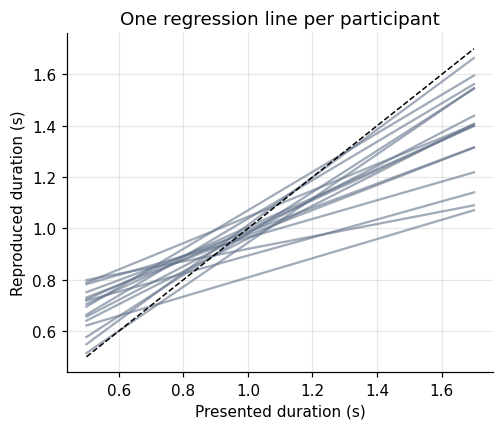

In [6]:
per_sub = (df.groupby("subject")
             .apply(lambda g: pd.Series(np.polyfit(g["dur_c"], g["reproduction"], 1),
                                        index=["slope", "intercept"]), include_groups=False))
print(per_sub.describe().loc[["mean", "std", "min", "max"]].round(3))

fig, ax = plt.subplots(figsize=(5, 4))
xs = np.linspace(-0.6, 0.6, 2)
for _, row in per_sub.iterrows():
    ax.plot(xs + 1.1, row["intercept"] + row["slope"] * xs, color="#64748b", alpha=0.6)
ax.plot(xs + 1.1, xs + 1.1, "k--", lw=1)
ax.set(xlabel="Presented duration (s)", ylabel="Reproduced duration (s)",
       title="One regression line per participant")
plt.show()

Slopes range widely across participants. A model that ignores this treats between-participant
variability as if it were measurement noise.

## Linear mixed model

A linear mixed model keeps the population-level (*fixed*) effects and adds participant-level
(*random*) deviations:

$$y_{ij} = (\beta_0 + u_{0i}) + (\beta_1 + u_{1i})\, x_{ij} + \dots + \varepsilon_{ij}, \qquad
\begin{bmatrix}u_{0i}\\u_{1i}\end{bmatrix} \sim \mathcal N(\mathbf 0, \Sigma_u).$$

Each participant gets their own intercept and slope, drawn from a population distribution whose
spread is estimated from the data. Fixed effects are then tested against between-participant
variability, which is the variability that matters for generalising to new people.

In [7]:
lmm = smf.mixedlm("reproduction ~ dur_c * C(load)", data=df,
                  groups=df["subject"], re_formula="~dur_c").fit(reml=True)
print(lmm.summary())

            Mixed Linear Model Regression Results
Model:             MixedLM  Dependent Variable:  reproduction
No. Observations:  5744     Method:              REML        
No. Groups:        16       Scale:               0.0461      
Min. group size:   351      Log-Likelihood:      614.9636    
Max. group size:   360      Converged:           Yes         
Mean group size:   359.0                                     
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           1.034    0.019 53.688 0.000  0.996  1.072
C(load)[T.3]        0.000    0.007  0.007 0.994 -0.014  0.014
C(load)[T.5]       -0.005    0.007 -0.685 0.494 -0.018  0.009
dur_c               0.592    0.051 11.665 0.000  0.493  0.692
dur_c:C(load)[T.3] -0.005    0.016 -0.311 0.756 -0.037  0.027
dur_c:C(load)[T.5] -0.023    0.016 -1.379 0.168 -0.055  0.009
Group Var           

statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


Compare the two tables. The fixed-effect estimates are similar, but the standard error of the
duration slope is several times larger in the mixed model, because it now reflects how much the
slope varies from person to person. That is the honest uncertainty about the population slope.
The load terms move the other way: load varies *within* each participant, so once stable
individual differences are modelled their standard errors shrink slightly.

The answer to the experimental question is clear either way. The average slope is about 0.59,
a strong central tendency, and memory load changes it by at most a few hundredths. Holding items
in working memory does not detectably change how strongly the prior pulls in this experiment.

In [8]:
compare = pd.DataFrame({
    "OLS est": ols_all.params, "OLS SE": ols_all.bse,
    "LMM est": lmm.fe_params, "LMM SE": lmm.bse[lmm.fe_params.index],
}).round(4)
print(compare)

                    OLS est  OLS SE  LMM est  LMM SE
Intercept            1.0338  0.0055   1.0339  0.0193
C(load)[T.3]         0.0004  0.0078   0.0001  0.0069
C(load)[T.5]        -0.0046  0.0078  -0.0047  0.0069
dur_c                0.5926  0.0130   0.5924  0.0508
dur_c:C(load)[T.3]  -0.0045  0.0183  -0.0051  0.0164
dur_c:C(load)[T.5]  -0.0228  0.0183  -0.0225  0.0163


## Shrinkage

The participant-level estimates from a mixed model (fixed effect plus that participant's random
effect) are pulled towards the population mean compared with separate per-participant fits.
The pull is strongest when a participant's own data are least informative. With about 360
trials each, every participant here is well measured and the pull is negligible. To see it,
refit using only 15 random trials per participant, as one might have from a short session.

statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


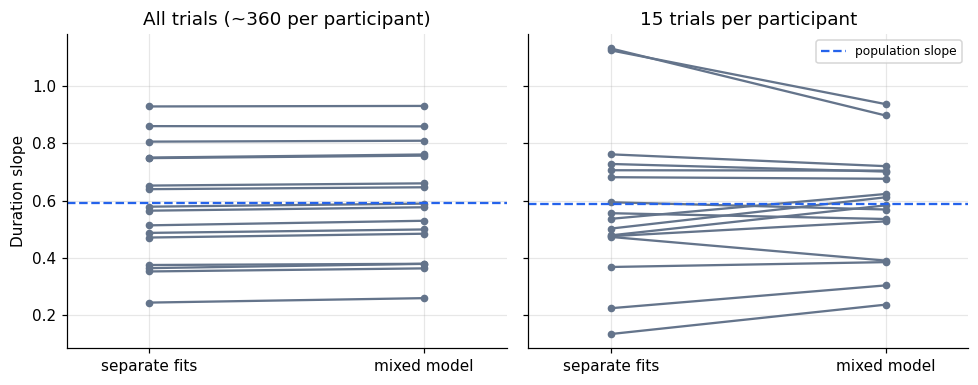

In [9]:
small = df.groupby("subject").sample(15, random_state=3)
sep_small = (small.groupby("subject")
                  .apply(lambda g: np.polyfit(g["dur_c"], g["reproduction"], 1)[0],
                         include_groups=False))
lmm_small = smf.mixedlm("reproduction ~ dur_c", data=small, groups=small["subject"],
                        re_formula="~dur_c").fit(reml=True)
re_small = pd.DataFrame(lmm_small.random_effects).T
mixed_small = lmm_small.fe_params["dur_c"] + re_small["dur_c"]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, sep, mixed, pop, title in [
        (axes[0], per_sub["slope"], lmm.fe_params["dur_c"] + pd.DataFrame(lmm.random_effects).T["dur_c"],
         lmm.fe_params["dur_c"], "All trials (~360 per participant)"),
        (axes[1], sep_small, mixed_small, lmm_small.fe_params["dur_c"], "15 trials per participant")]:
    for s_ in sep.index:
        ax.plot([0, 1], [sep.loc[s_], mixed.loc[s_]], color="#64748b", marker="o", ms=4)
    ax.axhline(pop, color="#2563eb", ls="--", label="population slope")
    ax.set(xticks=[0, 1], xticklabels=["separate fits", "mixed model"], xlim=(-0.3, 1.3),
           title=title)
axes[0].set_ylabel("Duration slope")
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

With little data per participant, the separate fits scatter widely, partly from noise. The
mixed model pulls them towards the population slope, trusting each participant's data only as
much as it deserves. This *partial pooling* is the same logic as a Bayesian prior, and it is the
reason hierarchical models are preferred whenever trial counts per participant are modest.

## Summary

- Least squares solves $X^\top X\boldsymbol\beta = X^\top\mathbf y$; every predictor is a column
  of $X$.
- A slope below 1 for reproduced on presented duration measures central tendency.
- Center continuous predictors so that intercepts and main effects stay interpretable.
- Trials nested in participants violate OLS independence; a mixed model with random intercepts
  and slopes gives honest standard errors for population effects.
- Mixed-model estimates for individual participants are shrunk towards the population mean.